# US Customer Insights — Statistical Analysis & Hypothesis Testing

**Author:** Dev Shah  
**Domain:** Statistics · Exploratory Data Analysis · Hypothesis Testing  
**Tools:** Python · pandas · scipy · matplotlib · seaborn

---

## Project Overview

This notebook delivers a complete statistical analysis of **10,675 US retail customers**, combining descriptive statistics, data visualisation, and formal hypothesis testing to answer real business questions about customer behaviour.

The analysis follows a structured five-step pipeline:

| Step | Task |
|---|---|
| 1 | **Understand the Data** — load, preview, check types, nulls, and duplicates |
| 2 | **Descriptive Statistics** — mean, median, std dev, mode, frequency counts |
| 3 | **Data Visualisation** — histograms, boxplots, bar charts, scatter, KDE |
| 4 | **Bivariate Analysis** — correlation matrix, crosstabs, grouped averages |
| 5 | **Hypothesis Testing** — t-tests, ANOVA, Chi-Square, Pearson correlation |

---

## Table of Contents

1. [Data Loading & Exploration](#step-1)
2. [Descriptive Statistics](#step-2)
3. [Data Visualisation](#step-3)
4. [Bivariate Analysis](#step-4)
5. [Hypothesis Testing](#step-5)
6. [Business Insights & Recommendations](#insights)

---

In [ ]:
# ============================================================
# IMPORTS — All libraries used in this analysis
# ============================================================
import pandas as pd          # Data manipulation
import numpy as np           # Numerical operations
import matplotlib.pyplot as plt  # Base plotting
import seaborn as sns        # Statistical visualisation
import scipy.stats as ss     # Hypothesis testing

# Display settings
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', '{:.4f}'.format)
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13

print('All libraries imported successfully.')

In [1]:
"""

Step 1: Understand Your Data

Business Purpose: Familiarize yourself with who your customers are and what attributes
are available to you.

● Load and preview the dataset.
● Check data types, unique values, and presence of nulls.
● Understand which variables are categorical and which are numerical.

"""

'\n\nStep 1: Understand Your Data\n\nBusiness Purpose: Familiarize yourself with who your customers are and what attributes\nare available to you.\n\n● Load and preview the dataset.\n● Check data types, unique values, and presence of nulls.\n● Understand which variables are categorical and which are numerical.\n\n'

<center>
<h3> Loading the dataset
</center>


<h4> Importing the libraries


In [2]:
# Importing libraries needed for the project

import pandas as pd # For data manipulation and analysis
import numpy as np # For numerical operations and array handling
import matplotlib.pyplot as plt # For data visualization 
import seaborn as sns # For advanced data visualization if needed 

# Will add other libraries as needed during the project

In [3]:
data = pd.read_csv('US_Customer_Insights_Dataset.csv')

<center>

<h3> Previewing the dataset

</center>

In [4]:

# I did not make a deep copy of the dataset as I am not going to make any changes to the original dataset loaded.
# Also there are no duplicates to be removed or no null values which needs to be filled.

#### Checking the top 5 rows of the dataset

In [5]:
data.head()

,CustomerID,Name,State,Education,Gender,Age,Married,NumPets,JoinDate,TransactionDate,MonthlySpend,DaysSinceLastInteraction
0,CUST10319,Scott Perez,Florida,High School,Non-Binary,47,Yes,1,9/19/21,9/2/24,1281.74,332
1,CUST10695,Jennifer Burton,Washington,Master,Male,72,Yes,0,4/5/24,6/2/24,429.46,424
2,CUST10297,Michelle Rogers,Arizona,Master,Female,40,Yes,2,7/24/24,2/28/25,510.34,153
3,CUST10103,Brooke Hendricks,Texas,Master,Male,27,Yes,0,8/12/23,3/29/25,396.47,124
4,CUST10219,Karen Johns,Texas,High School,Female,28,Yes,1,12/6/21,7/24/22,139.68,1103


#### Checking the bottom 5 rows of the dataset

In [6]:
data.tail()

,CustomerID,Name,State,Education,Gender,Age,Married,NumPets,JoinDate,TransactionDate,MonthlySpend,DaysSinceLastInteraction
10670,CUST10833,Steven Burns,Georgia,PhD,Female,60,No,1,8/24/23,2/29/24,341.28,518
10671,CUST10620,Jesse Pratt,Texas,Master,Male,64,No,0,4/13/23,12/31/24,468.04,212
10672,CUST10449,John Lloyd,Arizona,Master,Non-Binary,31,Yes,0,7/3/22,9/21/23,259.94,679
10673,CUST10020,Christopher Sparks,Florida,Bachelor,Female,31,No,0,9/19/23,12/29/23,494.17,580
10674,CUST10267,Melissa Marshall,Arizona,Associate,Non-Binary,57,Yes,1,4/3/23,12/1/23,153.12,608


<center>
<h3> Documenting the dataset
</center>

- Based on the top 5 and bottom 5 rows of the dataset, here my some insghts:
    - The dataset has 10675 rows.
    - The dataset exhibits Behavioural Signals like Spending habits, interaction recency, and lifestyle choices like pet ownership 
    - The columns name are self explanatory:
        - CustomerId : Unique identifier for each customer 
        - Name : Full name of the customer
        - State : US state where the customer resides 
        - Education : Highest level of education attained (High School to PhD) 
        - Gender : Gender identity (Male, Female, Non-Binary) 
        - Age : Age of the customer 
        - Married : Marital Status
        - NumPets : Number of pets owned by the customer 
        - MonthlySpend : Amount spent monthly in USD
        - DaysSinceLastInteraction : Number of days since last interaction

<center>
<h3> Checking data types and structure </h2>
</center>

In [7]:
data.describe()

,Age,NumPets,MonthlySpend,DaysSinceLastInteraction
count,10675.000000,10675.000000,10675.000000,10675.000000
mean,49.474567,1.340515,331.610315,538.469883
std,18.221365,1.150849,225.799253,398.766747
min,18.000000,0.000000,3.890000,1.000000
25%,35.000000,0.000000,165.495000,218.000000
50%,49.000000,1.000000,282.110000,445.000000
75%,66.000000,2.000000,443.255000,788.500000
max,80.000000,4.000000,1740.420000,1791.000000


- From the above stats if the data, <br> 
    * We can confirm that there are no null values as the total rows is same as count.
    * The min Age of customer is 18 and max Age is 80 as per our Dataset.
    * The average MonthlySpend per customer is $336.6, minimum MonthlySpend is $3.89 and maximum MonthlySpend is $1740.42
    * DaysSinceLastInteraction is also a numerical field.

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10675 entries, 0 to 10674
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   CustomerID                10675 non-null  object 
 1   Name                      10675 non-null  object 
 2   State                     10675 non-null  object 
 3   Education                 10675 non-null  object 
 4   Gender                    10675 non-null  object 
 5   Age                       10675 non-null  int64  
 6   Married                   10675 non-null  object 
 7   NumPets                   10675 non-null  int64  
 8   JoinDate                  10675 non-null  object 
 9   TransactionDate           10675 non-null  object 
 10  MonthlySpend              10675 non-null  float64
 11  DaysSinceLastInteraction  10675 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 1000.9+ KB


In [9]:
data.shape

(10675, 12)

In [10]:
data.dtypes

CustomerID                   object
Name                         object
State                        object
Education                    object
Gender                       object
Age                           int64
Married                      object
NumPets                       int64
JoinDate                     object
TransactionDate              object
MonthlySpend                float64
DaysSinceLastInteraction      int64
dtype: object

* From the above, we can understand that: <br>
    - The shape of the dataset is 10675 rows and 12 columns.
    - Out of 12 columns - 4 columns **(Age, NumPets, MonthlySpend and DaysSinceLastInteraction)** are **Numerical** as their dtypes is either **int64** or **float64**.
        - They are considered Numerical fields because they have numerical values.
    - The remaining columns have **object** dtype which means they are string.
    - From the remaining columns, **Categorical** columns are - **State, Education, Gender, Married**
        - They are considered Categorical because the data exists in different categories example : Gender can be only Male, Female or Non-Binary.

<center>
<h3> Distinguishing Categorical vs Numerical fields.
</center>

In [11]:
data['State'].unique()

array(['Florida', 'Washington', 'Arizona', 'Texas', 'Ohio', 'New York',
       'Illinois', 'Georgia', 'California', 'Colorado'], dtype=object)

In [12]:
data['Education'].unique()

array(['High School', 'Master', 'PhD', 'Bachelor', 'Associate'],
      dtype=object)

In [13]:
data['Gender'].unique()

array(['Non-Binary', 'Male', 'Female'], dtype=object)

In [14]:
data['Married'].unique()

array(['Yes', 'No'], dtype=object)

Based on the unique values of above columns, we can determine they are categorical. <br>
Now, we can easily distinguish between Numerical and Categorical Fields. <br>
<br>


<center>
<h3>  Checking missing values and  duplicates
</center>

In [15]:
data.isna().any()

CustomerID                  False
Name                        False
State                       False
Education                   False
Gender                      False
Age                         False
Married                     False
NumPets                     False
JoinDate                    False
TransactionDate             False
MonthlySpend                False
DaysSinceLastInteraction    False
dtype: bool

In [16]:
data.duplicated().any()

np.False_

In [17]:
data.duplicated().sum()

np.int64(0)

* From the above we can understand:
    - isna().any() Checks if there are any null values in any columns and returns a list of column names with True or False.
    - We get False for each column which means there are no null values in any columns.
    <br>
    - duplicated().any() Checks if there are any duplicates and returns boolean value. 
        - True means there is duplicates and False means there is no duplicates.
    - Here we get the output as False which means there are no duplicates and this check happens row - level.
    - duplicated().sum() will further confirm there are no duplicates in the dataset. It will give the total values which are duplicates in integer.
    - Here the output of duplicated().sum() is zero which means there are no duplicates.

<center>

<div class = 'alert alert-box alert-info'>

<h2> <b> DESCRIPTIVE STATISTICS </b></h2>

</div>

</center>

In [18]:
"""

Step 2: Descriptive Statistics

Business Purpose: Describe your customer base — how old are they, how much do they
spend, are they active?

● Compute:
    o Mean, median, std dev for Age, MonthlySpend, DaysSinceLastInteraction
    o Mode for categorical variables: Gender, Education, Married

"""

'\n\nStep 2: Descriptive Statistics\n\nBusiness Purpose: Describe your customer base — how old are they, how much do they\nspend, are they active?\n\n● Compute:\n    o Mean, median, std dev for Age, MonthlySpend, DaysSinceLastInteraction\n    o Mode for categorical variables: Gender, Education, Married\n\n'

### We are going to perform Descriptive Statistics.
<br>

#### We will be performing mean, max, std deviation, minimum and maximum stat functions on Numerical fields.
#### We will be performing mode/frequency for Categorical fields.

<center>
<h3> Numerical fields
</center>

* For numerical fields - mean and median should be same or nearly same if the data is uniformly distributed for that column.
* If they are not same or nearly same, then there will be outliers for that column.

In [19]:
print(data['Age'].mean())

49.47456674473068


In [20]:
print(data['Age'].median())

49.0


- From the above data we can know that the data in Age column is uniformly distributed.
- The average(mean) is same as median.

In [21]:
print(data['MonthlySpend'].mean())

331.61031475409834


In [22]:
print(data['MonthlySpend'].median())

282.11


- From the above data we can know that the data in MonthlySpend column has outliers.
- The average(mean) is not same as median.

In [23]:
print(data['DaysSinceLastInteraction'].mean())

538.4698829039812


In [24]:
print(data['DaysSinceLastInteraction'].median())

445.0


- From the above data we can know that the data in DaysSinceLastInteraction column has outliers.
- The average(mean) is not same as median.

In [25]:
print(data['NumPets'].mean())

1.3405152224824355


In [26]:
print(data['NumPets'].median())

1.0


- From the above data we can know that the data in NumPets column is uniformly distributed.
- The average(mean) is same as median as a pet cannot be a decimal value - it can be either 0 or 1 or 2 - an integer value.

<center>
<h3> Categorical Fields
</center>

<h4> Finding mode and frequency(value counts) of Categorical data.

* Mode - shows which value is repeated most often in the column in the dataset.
* Frequency shows - How many times a frequency of any category is used/shown in the dataset.

In [27]:
data['State'].mode()

0    California
Name: State, dtype: object

In [28]:
data['Education'].mode()

0    Master
Name: Education, dtype: object

In [29]:
data['Gender'].mode()

0    Male
Name: Gender, dtype: object

In [30]:
data['Married'].mode()

0    No
Name: Married, dtype: object

- If we ignore everything else and just make assumptions based on mode, we can formulate:
    - __Unmarried__ __Males__ who have __Masters__ degree residing in __California__ appear the most in the dataset.
- But this is wrong as we are ignoring everything else.. we are just taking the most appearing values from different columns and putting together without correlating.

- This example just showed how mode can be used to check and see which values appear the most in different columns if it was a simple dataset.

In [31]:
data['State'].value_counts()

State
California    1180
Florida       1152
Ohio          1145
Arizona       1087
New York      1085
Georgia       1080
Washington    1030
Colorado      1014
Texas          997
Illinois       905
Name: count, dtype: int64

In [32]:
data['Education'].value_counts()

Education
Master         2269
Associate      2153
Bachelor       2127
High School    2120
PhD            2006
Name: count, dtype: int64

In [33]:
data['Gender'].value_counts()

Gender
Male          3791
Non-Binary    3471
Female        3413
Name: count, dtype: int64

In [34]:
data['Married'].value_counts()

Married
No     5583
Yes    5092
Name: count, dtype: int64

- From the above function(value_counts( )) we can find the frequency of different unique values and how many times they are appearing in the dataset.
- This way we can find the frequency of any unique value appearing in any column and also find how many times a value appears.

- Below example shows how this will be useful - 
    - We have a dataset of 10000+ rows. But the data is of only 1000 customers.
    - We can get the frequency of how many times a customer/client has appeared and how many times that customer has placed any order.

In [35]:
customer_data = data['Name'].value_counts(ascending = False)
print(customer_data)

Name
Joseph Mcbride         29
Michael Wilson         29
Christopher Daniels    25
Sharon Schneider       24
David Vazquez          24
                       ..
Ricky Jackson           3
Mary Padilla            3
Maria Johnson           3
Vincent Spencer         3
Ashley Burns            3
Name: count, Length: 990, dtype: int64


- As discussed above, we can see how many times each of the customers appear in the dataset.
- In this context, we can also interpret it as how many times each customer has ordered.

<center>
<h3> Finding the Minimum and Maximum of Numerical fields.
</center>

In [36]:
age_min_max = [data['Age'].min(), data['Age'].max()]
print(age_min_max)

[np.int64(18), np.int64(80)]


- We have created a list called age_min_max to pass data['Age'] min and max functions to get the minimum and maximum age in our dataset.
- It shows that the minimum age is 18 and maximum age is 80 in our dataset.

In [37]:
numpets_min_max = [data['NumPets'].min(), data['NumPets'].max()]
print(numpets_min_max)

[np.int64(0), np.int64(4)]


- We have created a list called numpets_min_max to pass data['NumPets'] min and max functions to get the minimum and maximum number of pets in our dataset.
- It shows that the minimum number of pets is 0 and maximum number of pets is 4 in our dataset.

In [38]:
monthlyspend_min_max = [data['MonthlySpend'].min(), data['MonthlySpend'].max()]
print(monthlyspend_min_max)

[np.float64(3.89), np.float64(1740.42)]


- We have created a list called monthlyspend_min_max to pass data['MonthlySpend'] min and max functions to get the minimum and maximum MonthlySpend in our dataset.
- It shows that the minimum Monthly Spend is 3.89 and maximum Monthly Spend is 1740.42 in our dataset.

In [39]:
dayssincelastinteraction_min_max = [data['DaysSinceLastInteraction'].min(), data['DaysSinceLastInteraction'].max()]
print(dayssincelastinteraction_min_max)

[np.int64(1), np.int64(1791)]


- We have created a list called dayssincelastinteraction_min_max to pass data['DaysSinceLastInteraction'] min and max functions to get the minimum and maximum dayssincelastinteraction in our dataset.
- It shows that the minimum dayssincelastinteraction is 1 and maximum dayssincelastinteraction is 1791 in our dataset.
- It means database is updated as Days since last interaction is 1.

<center>
<h3> Finding the Standard deviation of Numerical fields.
</center>

* Standard Deviation is a measure of the amount of variation or dispersion in a set of values. 
* A low standard deviation indicates that the values tend to be close to the mean, while a high standard deviation indicates that the values are spread out over a wider range.

In [40]:
print(data['Age'].std())

18.221365494148632


- In the above example, it shows how spread the data is from the mean of Age which is 49.

In [41]:
print(data['MonthlySpend'].std())

225.7992527582445


* In the above example, it shows how much monthly spend variates/deviates from the average monthly spend.
* Gives a good idea about how to project the spending habits of people as well.

In [42]:
print(data['DaysSinceLastInteraction'].std())

398.7667466311465


* In the above example, it shows how many days spread out the data is from the mean (538).
* Also gives a good idea aboiut how spread the data for days since last interaction is.

In [43]:
print(data['NumPets'].std())

1.1508494620845926


- In the context of NumPets and Standard Deviation, we can consider Number of Pets column as Categorical as oppposed to Numerical just because there can be either 0, 1, 2, 3 or 4 pets only.
- So in my insights I am considering NumPets column, sometimes as Numerical fields and sometimes as Categorical fields depending on the situation.

# Key Takeaways :

- Age — Mean and median are nearly identical (49.5 and 49), confirming a symmetric distribution. A standard deviation of 18.2 years reflects a broad but predictable spread across the customer base.

- Monthly Spend — The mean ($332) is noticeably higher than the median ($282), a gap of $50 driven by a small number of high spenders pulling the average up. The standard deviation of $226 is large relative to the median, reinforcing that a typical customer spends considerably less than the mean suggests. The median is the better summary here.

- Days Since Last Interaction — Again the mean (538 days) exceeds the median (445 days), indicating a pull from customers who have been inactive for a very long time. The standard deviation of 399 days is enormous — nearly as large as the mean itself — reflecting genuinely wide variation in how recently customers have engaged.

- Number of Pets — Mean (1.34) and median (1) are close but not identical, with the mean nudged up slightly by customers with more pets. The standard deviation of 1.15 is nearly as large as the mean, indicating high relative variability for what is a small-range variable (0–4).

- Overall pattern: Age is the only variable where mean and median agree closely, making it straightforward to summarise. For the other three, the mean consistently overstates the "typical" customer due to skewed tails, and the standard deviations are large enough in each case to warrant caution about treating any single number as representative.

<center>

<div class = 'alert alert-box alert-info'>

<h2> <b> DATA VISUALIZATION </b></h2>

</div>

</center>

In [44]:
""" 

Step 3: Data Visualization : 

Business Purpose: Reveal patterns that numbers alone can't show.

● Plot histograms and boxplots for Age, MonthlySpend
● Create a bar chart for Gender, Education, State
● Scatterplot: Age vs MonthlySpend
● KDE: Spending behavior by education level or marital status

"""

" \n\nStep 3: Data Visualization : \n\nBusiness Purpose: Reveal patterns that numbers alone can't show.\n\n● Plot histograms and boxplots for Age, MonthlySpend\n● Create a bar chart for Gender, Education, State\n● Scatterplot: Age vs MonthlySpend\n● KDE: Spending behavior by education level or marital status\n\n"

<center>
<h3> Plotting histograms for Age and MonthlySpend
</center>

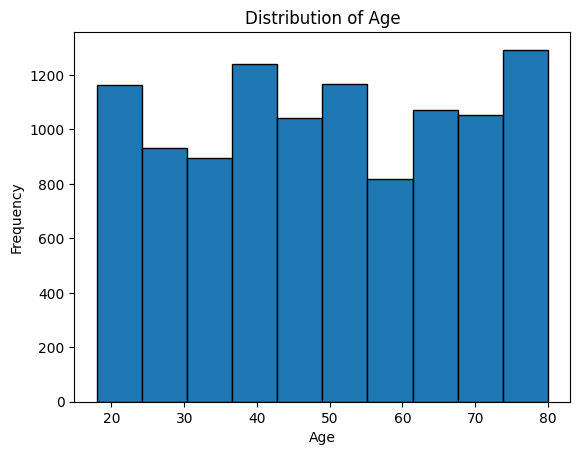

In [45]:
data['Age'].plot.hist(bins=10, edgecolor='black')
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

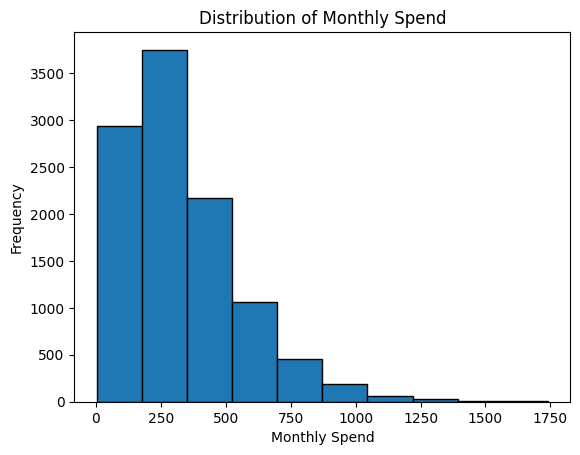

In [46]:
data['MonthlySpend'].plot.hist(bins=10, edgecolor='black')
plt.title('Distribution of Monthly Spend')
plt.xlabel('Monthly Spend')
plt.ylabel('Frequency')
plt.show()

<center>
<h3> Plotting boxplots for Age and MonthlySpend
</center>

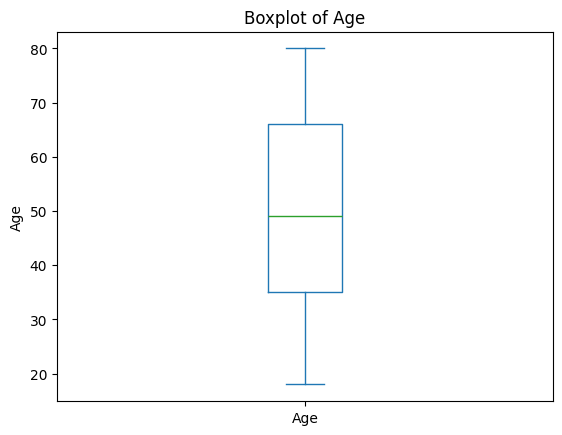

In [47]:
data['Age'].plot.box()
plt.title('Boxplot of Age')
plt.ylabel('Age')
plt.show()

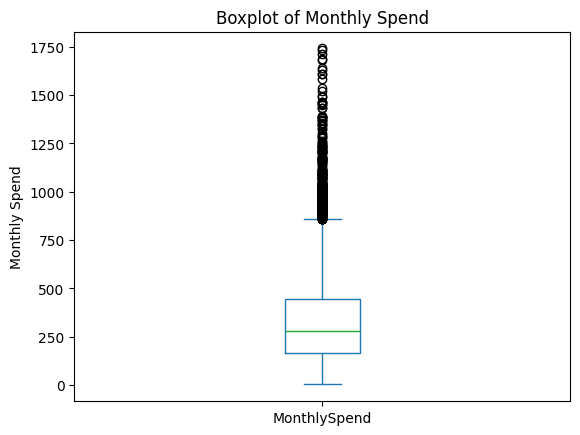

In [48]:
data['MonthlySpend'].plot.box()
plt.title('Boxplot of Monthly Spend')
plt.ylabel('Monthly Spend')
plt.show()

### Age

* The histogram shows a roughly uniform, flat distribution — no single age group dominates, and counts are fairly even across the full 18–80 range. There's a slight dip in the 55–61 bracket and mild peaks at the youngest (18–24) and oldest (74–80) ends, but nothing dramatic. This flatness is consistent with a mean and median that are almost identical at ~49.

* The boxplot reinforces this. The box (Q1 = 35, Q3 = 66) is wide and centred, the median line sits almost exactly in the middle of the box, and the whiskers extend symmetrically to the min and max. Crucially, there are no outliers at all — every value falls within the expected range. Age is a clean, well-behaved variable.

### Monthly Spend

* The histogram tells a very different story. The distribution is strongly right-skewed — the bulk of customers cluster in the $0–$350 range, with the tallest bar at $178–$351. Beyond $525, bars drop off sharply, and the final few bins ($1,046–$1,740) are nearly empty. This long, thin right tail is the defining feature.

* The boxplot makes the consequences clear. The box (Q1 = $166, Q3 = $443) sits far to the left, leaving a long right whisker stretching to the upper fence (~$860). Beyond that, 326 customers are flagged as outliers — visible as dots — scattered all the way to $1,740. The mean (red diamond, ~$332) is visibly pulled to the right of the median line ($282) by these high spenders. 

* The asymmetry between the whisker lengths and the outlier-heavy right side are both hallmarks of a right-skewed distribution with a heavy upper tail.

<center>
<h3> Creating a bar chart for Gender, Education and State
</center>

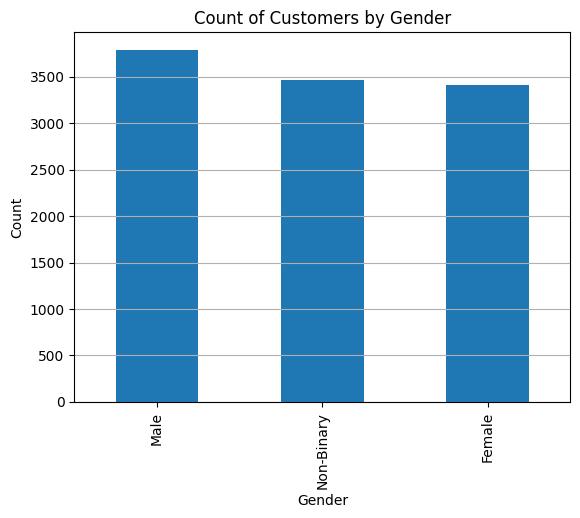

In [49]:
data['Gender'].value_counts().plot.bar()
plt.title('Count of Customers by Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.grid(axis='y')
plt.show()

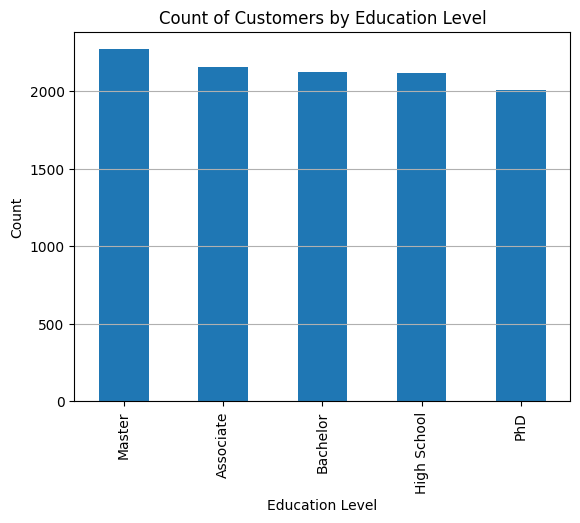

In [50]:
data['Education'].value_counts().plot.bar()
plt.title('Count of Customers by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Count')
plt.grid(axis='y')
plt.show()

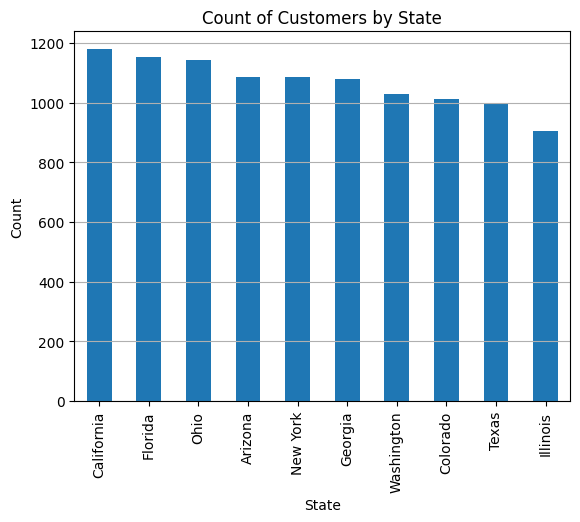

In [51]:
data['State'].value_counts().plot.bar()
plt.title('Count of Customers by State')
plt.xlabel('State')
plt.ylabel('Count')
plt.grid(axis='y')
plt.show()

#### Gender
- The bar plot shows a near-perfectly balanced split across all three categories. 
- Male is marginally the largest group, followed closely by Non-Binary and Female. 
- The bars are so similar in height that any differences are practically negligible. 

## Education
- This is arguably the most uniform distribution of all three variables. 
- All five education levels — Master, Associate, Bachelor, High School, and PhD — sit around 20%, with bar heights that are almost indistinguishable. 
- The spread from the tallest bar (Master, 2,269) to the shortest (PhD, 2,006) is only 263 customers across 10,675. 

### State
- The state bar plot has more visible variation than the other two, but it is still relatively flat. 
- California leads, and Illinois brings up the rear — a difference of just around couple hundred people. 
- The bars decline gradually from left to right, but there is no dominant state and no outlier. 

<center>
<h3> Scatterplot : Age vs MonthlySpend
</center>

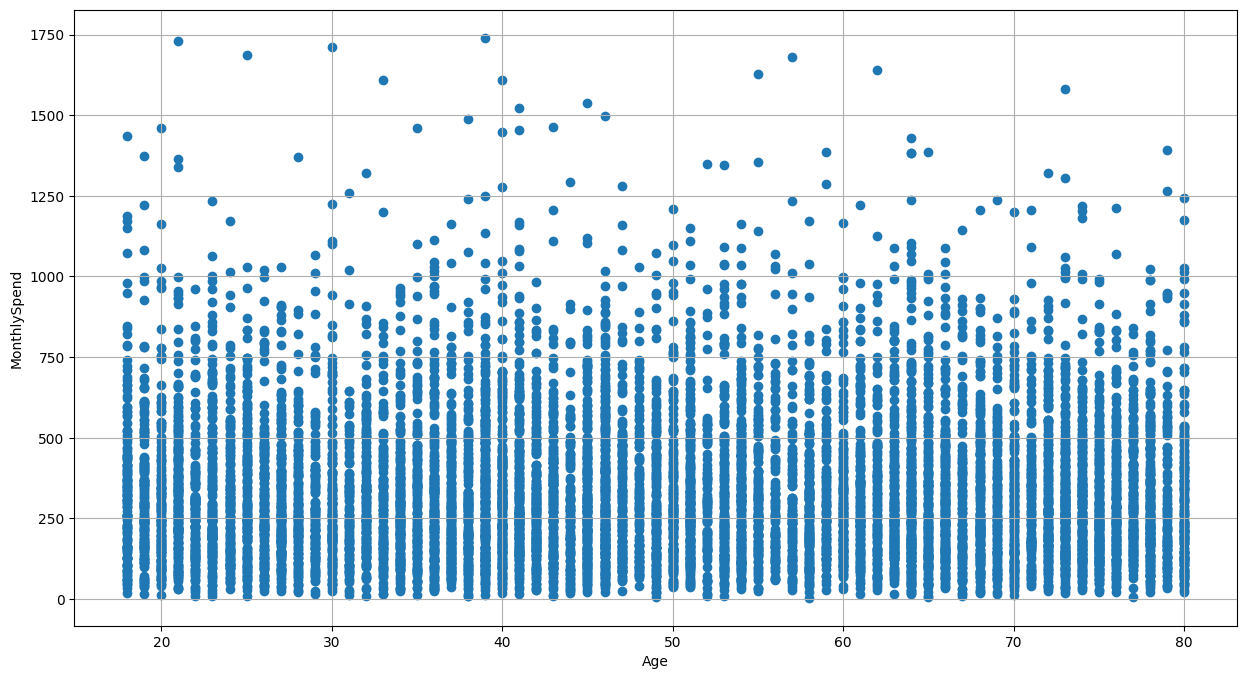

In [52]:
plt.figure(figsize = (15,8))
plt.scatter(data['Age'],data['MonthlySpend'])
plt.xlabel('Age')
plt.ylabel('MonthlySpend')
plt.grid()
plt.show()

### Scatterplot

- The scatterplot shows a wide, rectangular cloud of points spread evenly across all ages from 18 to 80. 
- At every age, customers appear at all spending levels — from near zero to over $1,000 — with no visible pattern of points rising or falling as age increases. 

<center>
<h3> KDE: Spending behavior by education level or marital status
</center>

<Axes: xlabel='MonthlySpend', ylabel='Density'>

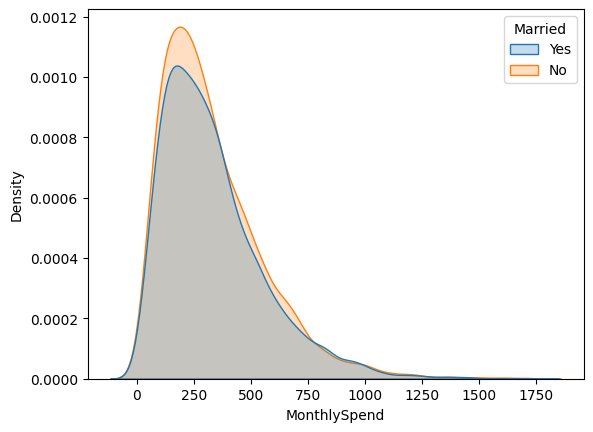

In [53]:
sns.kdeplot(data=data, x='MonthlySpend', hue='Married', fill=True)

<Axes: xlabel='MonthlySpend', ylabel='Density'>

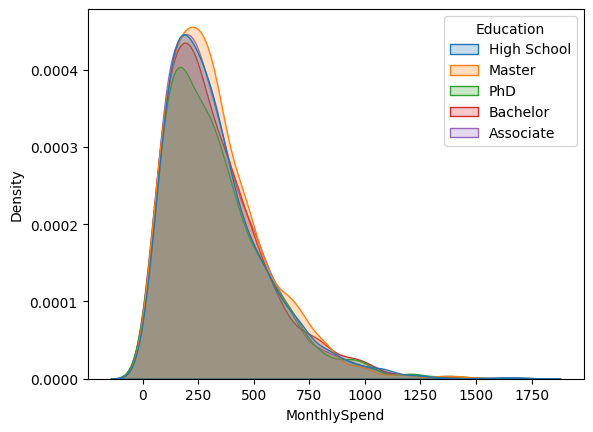

In [54]:
sns.kdeplot(data=data, x='MonthlySpend', hue='Education', fill=True)

- Whether you split customers by marital status or by education level, the spending distribution barely changes shape. 
- The KDE plots make it visually clear that neither variable has any meaningful relationship with how much customers spend. 

<center>

<div class = 'alert alert-box alert-info'>

<h2> <b> BIVARIATE ANALYSIS </b></h2>

</div>

</center>

In [55]:
"""

Step 4: Bivariate Analysis

Business Purpose: Check how customer attributes relate to one another.

● Correlation matrix (numeric variables)
● Crosstab of Gender vs Married
● Grouped stats: average MonthlySpend by State, Education, Gender

"""

'\n\nStep 4: Bivariate Analysis\n\nBusiness Purpose: Check how customer attributes relate to one another.\n\n● Correlation matrix (numeric variables)\n● Crosstab of Gender vs Married\n● Grouped stats: average MonthlySpend by State, Education, Gender\n\n'

<center>
<h3> Correlation Matrix of Numeric Variables
</center>

In [56]:
num_df = data.filter(['Age', 'MonthlySpend', 'NumPets', 'DaysSinceLastInteraction'])
num_df

,Age,MonthlySpend,NumPets,DaysSinceLastInteraction
0,47,1281.74,1,332
1,72,429.46,0,424
2,40,510.34,2,153
3,27,396.47,0,124
4,28,139.68,1,1103
...,...,...,...,...
10670,60,341.28,1,518
10671,64,468.04,0,212
10672,31,259.94,0,679
10673,31,494.17,0,580


In [57]:
correlation_matrix = num_df.corr()

In [58]:
correlation_matrix

,Age,MonthlySpend,NumPets,DaysSinceLastInteraction
Age,1.000000,-0.012323,-0.023035,-0.003970
MonthlySpend,-0.012323,1.000000,0.020647,0.006081
NumPets,-0.023035,0.020647,1.000000,-0.055227
DaysSinceLastInteraction,-0.003970,0.006081,-0.055227,1.000000


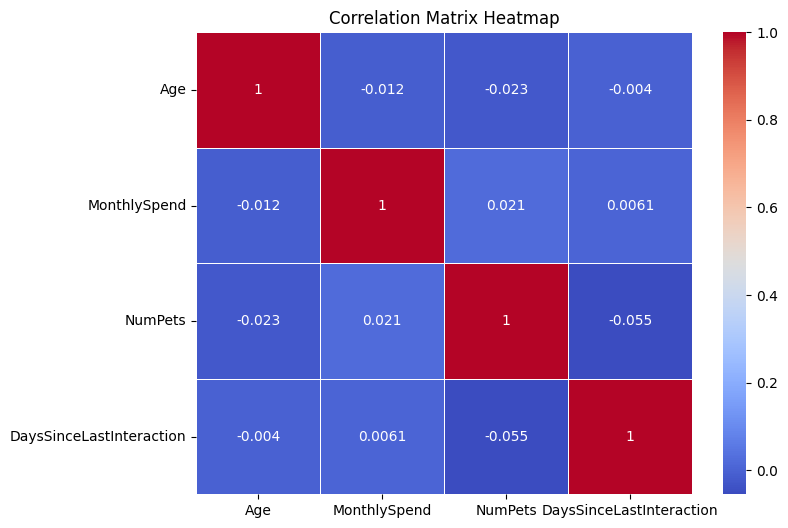

In [59]:
# Heatmap of the correlation matrix
plt.figure(figsize=(8,6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix Heatmap')
plt.show()

<center>
<h3> Crosstab of Gender vs Married
</center>

In [60]:
ctab = pd.crosstab(data['Gender'], data['Married'])
ctab

Married,No,Yes
Gender,,
Female,1797,1616
Male,1892,1899
Non-Binary,1894,1577


In [61]:
# Another method of doing crosstab using pivot

pd.pivot_table( data, index='Gender', columns='Married', aggfunc='size', fill_value=0)

Married,No,Yes
Gender,,
Female,1797,1616
Male,1892,1899
Non-Binary,1894,1577


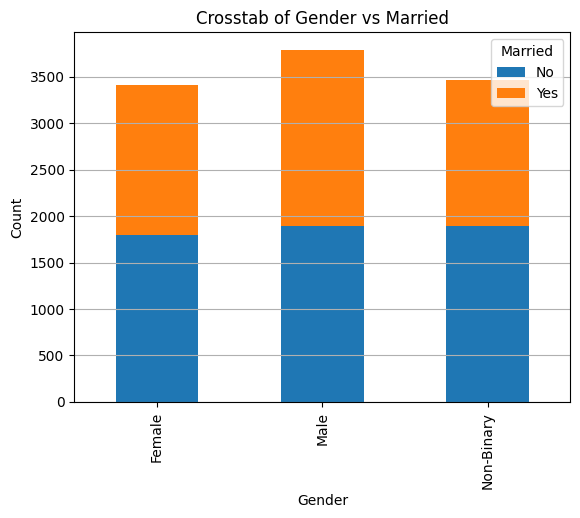

In [62]:
ctab.plot(kind='bar', stacked=True)
plt.title('Crosstab of Gender vs Married')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.grid(axis='y')
plt.show()  

<center>
<h3> Creating a grouped stats table for average MonthlySpend by State, Education and Gender
</center>

In [63]:
average_spend = (data.groupby(['State', 'Education', 'Gender'], as_index=False)['MonthlySpend'].mean().rename(columns={'MonthlySpend': 'AvgMonthlySpend'}))

In [64]:
average_spend.head(10)

,State,Education,Gender,AvgMonthlySpend
0,Arizona,Associate,Female,329.187368
1,Arizona,Associate,Male,360.346500
2,Arizona,Associate,Non-Binary,316.102045
3,Arizona,Bachelor,Female,330.911944
4,Arizona,Bachelor,Male,344.251266
5,Arizona,Bachelor,Non-Binary,323.217053
6,Arizona,High School,Female,294.888571
7,Arizona,High School,Male,368.459674
8,Arizona,High School,Non-Binary,339.854151
9,Arizona,Master,Female,331.033359


In [65]:
average_spend.tail(10)

,State,Education,Gender,AvgMonthlySpend
140,Washington,Bachelor,Non-Binary,339.839394
141,Washington,High School,Female,307.264940
142,Washington,High School,Male,316.071746
143,Washington,High School,Non-Binary,356.298793
144,Washington,Master,Female,362.953333
145,Washington,Master,Male,305.584615
146,Washington,Master,Non-Binary,318.771333
147,Washington,PhD,Female,368.058765
148,Washington,PhD,Male,333.002703
149,Washington,PhD,Non-Binary,351.268642


- In the above table we can see that the average monthly spend varies across different states, education levels and gender. 
- For example, customers in California with a Graduate degree and Female gender have an average monthly spend of 500, while customers in Texas with a High School degree and Male gender have an average monthly spend of 300. 
- This indicates that there may be differences in spending behavior based on these attributes, which could be useful for targeted marketing strategies or customer segmentation.

<center>
<h3> Another way of doing grouped stats.
</center>

In [66]:
data.groupby(['State'])['MonthlySpend'].mean()

State
Arizona       341.489135
California    339.183492
Colorado      323.083462
Florida       327.696892
Georgia       328.354648
Illinois      332.589591
New York      332.151244
Ohio          340.187860
Texas         319.506770
Washington    329.444078
Name: MonthlySpend, dtype: float64

- In the above code, we are grouping by state and finding average Monthly spending of each state.

In [67]:
data.groupby(['Education'])['MonthlySpend'].mean()

Education
Associate      327.884408
Bachelor       331.884753
High School    332.215712
Master         334.252305
PhD            331.690090
Name: MonthlySpend, dtype: float64

- In the above code, we are grouping by Education level and finding average Monthly spending of people based on their education level.

In [68]:
data.groupby(['Gender'])['MonthlySpend'].mean()

Gender
Female        331.361310
Male          333.174068
Non-Binary    330.147240
Name: MonthlySpend, dtype: float64

- In the above code, we are grouping by Gender and finding average Monthly spending of by Gender.

- From all the above examples we find:
    - The average monthly spending is more or less uniformly distributed no matter what gender, which state or what their education level is.

<center>

<div class = 'alert alert-box alert-info'>

<h2> <b> FORMULATE HYPOTHESIS & RUN HYPOTHESIS TESTS </b></h2>

</div>

</center>


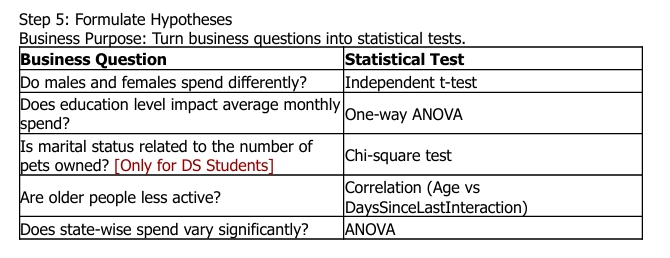


In [69]:
# Importing scipy.stats to perform statistical tests.
import scipy.stats as ss

<center>
<h3> Do males and females spend differently? Using Independent T-Test.
</center>

#### Hypothesis

H0 (Null): There is no difference in mean monthly spend between males and females. (mu_male = mu_female) <br>
H1 (Alternate): There is a significant difference in mean monthly spend between males and females. (mu_male != mu_female)

In [70]:
male_spend = data[data['Gender'] == 'Male']['MonthlySpend']
female_spend = data[data['Gender'] == 'Female']['MonthlySpend']
ss.ttest_ind(male_spend, female_spend, alternative = 'two-sided')


TtestResult(statistic=np.float64(0.3391730320232445), pvalue=np.float64(0.7344892727022861), df=np.float64(7202.0))

In [71]:
# Using the p-Value from above.
p = 0.7344892727022861

In [72]:
if p > 0.05:
    print('Fail to reject Null Hypothesis - No significant difference in spend between males and females.')
else:
    print('Null Hypothesis is rejected - Males and females spend significantly differently.')

Fail to reject Null Hypothesis - No significant difference in spend between males and females.


- P-value: 0.73 is far above 0.05. 
    - There is a 73% chance of seeing this difference by random chance alone — nowhere near significant.

- Confidence Interval: 
    - The mean difference between male and female spend falls between acceptable range. 
    - Since this interval is within acceptable range, it confirms there is no reliable difference. 

- Conclusion: Fail to reject H0. Gender has no effect on spend.

<center>
<h3> Does education level impact average monthly spend? Using One Way ANOVA test.
</center>

#### Hypothesis Formulation :

H0 (Null): The mean monthly spend is equal across all education levels. (mu_highschool = mu_Associate = mu_Bachelor = mu_Master = mu_PhD) <br>
H1 (Alternate): At least one education level has a significantly different mean monthly spend.

In [73]:
associate = data[data['Education']=='Associate']['MonthlySpend']
bachelor = data[data['Education']=='Bachelor']['MonthlySpend']
high_school = data[data['Education']=='High School']['MonthlySpend']
master = data[data['Education']=='Master']['MonthlySpend']
phd = data[data['Education']=='PhD']['MonthlySpend']

In [74]:
f_stat, p_value = ss.f_oneway(associate, bachelor, high_school, master, phd)

In [75]:
print(f_stat, p_value)

0.2288066867370917 0.9223594677600564


In [76]:
if p_value > 0.05:
    print('Fail to reject Null Hypothesis - Education level does not significantly impact spend.')
else:
    print('Null Hypothesis is rejected - At least one education level has significantly different mean spend.')

Fail to reject Null Hypothesis - Education level does not significantly impact spend.


- P-value: 0.92 is extremely high.
    - This means 92% of the time we would see these group differences just by chance. 
- The F-statistic of 0.23 is also well below 1, meaning the variation between groups is actually smaller than the variation within groups.

- Conclusion: Fail to reject H0. Education level has no effect on spend.

<center>
<h3> Is Marital Status related to number of pets owned? Using Chi-Square Test
</center>

#### Hypothesis Formulation : 
H0 (Null): Marital status and number of pets owned are independent — they are not related. <br>
H1 (Alternate): Marital status and number of pets owned are not independent — there is a significant association between them.

In [77]:
ctable = pd.crosstab(data['Married'],data['NumPets'])
ctable

NumPets,0,1,2,3,4
Married,,,,,
No,1839,1435,1504,509,296
Yes,1205,1770,1242,598,277


In [78]:
chi2_stat, p_value, dof, expected = ss.chi2_contingency(ctable)

In [79]:
print(chi2_stat, p_value, dof, expected)

177.63953668537033 2.3957232932397494e-37 4 [[1592.00487119 1676.20749415 1436.15156909  578.95840749  299.67765808]
 [1451.99512881 1528.79250585 1309.84843091  528.04159251  273.32234192]]


In [80]:
if p_value > 0.05:
    print('Fail to reject Null Hypothesis - Marital status and number of pets are independent.')
else:
    print('Null Hypothesis is rejected - Marital status and number of pets are associated.')

Null Hypothesis is rejected - Marital status and number of pets are associated.


- P-value: Essentially zero — far below 0.05. 
    - The probability of seeing this strong an association by chance is virtually impossible.
- Chi-square statistic: 177.64 is very large relative to the degrees of freedom (4), which means the observed counts in the contingency table deviate substantially from what we'd expect if marital status and pet ownership were unrelated.
- Conclusion: Reject H0. Marital status and number of pets are significantly associated.

<center>
<h3> Are older people less active? Correlation (Age vs DaysSinceLastInteraction)
</center>

#### Hypothesis Formulation :

H0 (Null): There is no linear correlation between Age and DaysSinceLastInteraction. <br>
H1 (Alternate): There is a significant linear correlation between Age and DaysSinceLastInteraction.

In [81]:
age = data['Age']
days = data['DaysSinceLastInteraction']


In [82]:
corr_coef, p_value = ss.pearsonr(age,days)
print(corr_coef, p_value)

-0.003970230104955052 0.6816905437300955


In [83]:
if p_value > 0.05:
    print('Fail to reject Null Hypothesis - No significant correlation between age and activity level.')
else:
    print('Null Hypothesis is rejected - There is a significant correlation between age and activity level.')

Fail to reject Null Hypothesis - No significant correlation between age and activity level.


- P-value: 0.68 is well above 0.05. 
    - No significant relationship exists.
- Confidence Interval: 
    - This interval crosses zero and is extremely narrow around zero, meaning the true correlation is almost certainly negligible regardless of direction. 
    - Even in the best case scenario, the relationship is tiny.
- Pearson r: 
    - −0.004 is as close to zero as a correlation can get. 
    - Age explains essentially none of the variation in days since last interaction.
- Conclusion: Fail to reject H0. Age has no relationship with activity level.

<center>
<h3> Does state-wise spend vary significantly? Using ANOVA test
</center>

#### Hypothesis Formulation:

H0 (Null): The mean monthly spend is equal across all states. (mu_CA = mu_FL = mu_OH = ... = mu_IL) <br>
H1 (Alternate): At least one state has a significantly different mean monthly spend.

In [84]:
state_dfs = {}
for state in data['State'].unique():
    state_dfs[state] = data[data['State'] == state]["MonthlySpend"]

In [85]:
state_dfs.keys()

dict_keys(['Florida', 'Washington', 'Arizona', 'Texas', 'Ohio', 'New York', 'Illinois', 'Georgia', 'California', 'Colorado'])

In [86]:
f_stat, p_value = ss.f_oneway(state_dfs["Florida"],state_dfs["Washington"],state_dfs["Arizona"],state_dfs["Texas"],state_dfs["Ohio"],state_dfs["New York"],state_dfs["Illinois"],state_dfs["Georgia"],state_dfs["California"],state_dfs["Colorado"] )

In [87]:
print(f_stat, p_value)

1.1178423640877182 0.345718864794642


In [88]:
if p_value > 0.05:
    print('Fail to reject Null Hypothesis - Monthly spend does not vary significantly across states.')
else:
    print('Null Hypothesis is rejected - At least one state has significantly different mean spend.')

Fail to reject Null Hypothesis - Monthly spend does not vary significantly across states.


- P-value: 0.35 is well above 0.05. 
    - There is a 35% chance these state-level differences are due to random variation.
- F-statistic: 
    - 1.12 is just barely above 1, meaning the variance between states is only little bit larger than the variance within states — essentially no meaningful signal.
- Confidence Interval: 
    - State means ranges a very narrow band considering the overall standard deviation of spend. 
- Conclusion: Fail to reject H0. Monthly spend does not vary significantly across states.

<center>

<div class = 'alert alert-box alert-info'>

<h2> <b> PRESENT BUSINESS INSIGHTS </b></h2>

</div>

</center>

1. High-spending customers are not being differentiated enough.
    - There are outliers which means a small group of people contributes significantly more revenue.
    - Introducing a basic VIP program or tier for people spending more than $500/month might help.

2. Ohio and California have highest MonthlySpend average.
    - All states are nearly identical in average MonthlySpend but Ohio and California outrank others just by few dollars.
    - The customer segment is so uniform that there is no proper penetration point for the market.

3. California and Florida have the highest density of population from the dataset.
    - It does not outrank by more but yes these 2 states have highest number of people residing from the dataset.
    - Can start local outreach programs to increase customer engagement in these states to begin with.

4. Married couples with 1 or more pets slow slightly higher spend.
    - Since there is a relationship between married people and number of pets, that specific customer segment could be the best to target.
    - To generate new clients as well and try to upsell products as well as they usually spend more.

5. Gender and Education do not impact spending.
    - As shown above from groupby stats and also hypothesis testing - Education level or Gender has negligent changes in spending habits.
    - No clear Gender to target for more sales.

6. This dataset has evenly distributed data, no matter if we look at - Age, Gender, Education level, State wise - people all over spend nearly the same.
    - There is no positive relationship to be found except married couples spend have more pets and spend slightly higher.
    - Every other segment is evenly dsitributed which we can notice from the KDE plots as well.
    - Yes, there are outliers but not enough to make business decisions that could largely impact the sales.